# 02 · wav2vec 2.0 training

Fine-tunes `facebook/wav2vec2-base` for spoof detection on ASVspoof 2019 LA train, selects the checkpoint on dev, and saves it with everything inference needs. No eval-set data is read here; scoring happens in notebook 03.

Inputs: notebook 00 output, `audio_utils.py` and `rawboost.py`. Requires a GPU and Internet (pre-trained weights).


Attention pooling over frames (its weights drive the attention view in the app) and the head `Linear(256) → BN → ReLU → Dropout(0.3) → Linear(1)`. Optimiser: AdamW with weight decay 1e-4 as in SSL-AASIST; learning rate 1e-5 for the encoder (as in the original notebook) and 1e-4 for the new layers, linear warm-up then cosine decay. Batch 14 as in SSL-AASIST. Up to 10 epochs, early stopping after 3 epochs without dev-EER improvement once 4 epochs have run.

In [1]:
import json
import math
import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import transformers
from torch.utils.data import DataLoader, Dataset
from transformers import Wav2Vec2Model

INPUT_ROOT = "/kaggle/input"
WORK_DIR = "/kaggle/working"
W2V_NAME = "facebook/wav2vec2-base"
SEED = 0
BATCH_SIZE = 14
EVAL_BATCH_SIZE = 64
EPOCHS = 10
MIN_EPOCHS = 4
PATIENCE = 3
LR_ENCODER = 1e-5
LR_HEAD = 1e-4
WEIGHT_DECAY = 1e-4
WARMUP_FRACTION = 0.1
GRAD_CLIP = 1.0
CLASS_WEIGHT = {"bonafide": 0.9, "spoof": 0.1}
NUM_WORKERS = os.cpu_count()
DEVICE = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
AMP = DEVICE.type == "cuda"
print(f"torch {torch.__version__}, transformers {transformers.__version__}, "
      f"{torch.cuda.get_device_name(0) if AMP else 'CPU only'}", flush=True)

torch 2.11.0+cu128, transformers 5.16.1, Tesla T4


In [2]:
def find_dir(required, max_depth=6):
    hits = set()
    for dirpath, dirnames, filenames in os.walk(INPUT_ROOT):
        depth = os.path.relpath(dirpath, INPUT_ROOT).count(os.sep)
        dirnames[:] = [] if depth >= max_depth else sorted(d for d in dirnames if d not in ("flac", "cache"))
        if set(required) <= set(filenames):
            hits.add(os.path.realpath(dirpath))
    if len(hits) != 1:
        raise FileNotFoundError(f"expected one directory with {required} under {INPUT_ROOT}, found {sorted(hits)}")
    return hits.pop()


for module_file in ("audio_utils.py", "rawboost.py"):
    sys.path.insert(0, find_dir([module_file]))
import audio_utils as U  # noqa: E402
import rawboost  # noqa: E402

U._self_test()
PREP_DIR = find_dir(["manifest.csv", "feature_stats.json", "provenance.json"])
with open(os.path.join(PREP_DIR, "provenance.json")) as fh:
    prep = json.load(fh)
if U.file_sha256(os.path.join(PREP_DIR, "manifest.csv")) != prep["manifest_sha256"]:
    raise AssertionError("manifest.csv does not match provenance.json")
for split in ("train", "dev"):
    if U.file_sha256(os.path.join(PREP_DIR, prep["cache"][split]["file"])) != prep["cache"][split]["sha256"]:
        raise AssertionError(f"{split} cache does not match provenance.json")

manifest = pd.read_csv(os.path.join(PREP_DIR, "manifest.csv"))
train_df = manifest[manifest["split"] == "train"].reset_index(drop=True)
dev_df = manifest[manifest["split"] == "dev"].reset_index(drop=True)
print(f"prep outputs from audio_utils {prep['utils_version']}, running {U.UTILS_VERSION}")
print(PREP_DIR, len(train_df), len(dev_df), DEVICE, flush=True)

audio_utils 1.0.1 self-test passed (sha 658e72bce982)
prep outputs from audio_utils 1.0.1, running 1.0.1
/kaggle/input/notebooks/rudranshiverma/00-data-prep 25380 24844 cuda:0


## Data

Workers read int16 audio from the cache. Each clip is normalised over its real samples to zero mean and unit variance, then zero-padded to 4 s; wav2vec2-base is used without an attention mask, as its padding convention requires. RawBoost runs on the full clip before cropping, as in the official implementation.

In [3]:
def normalise_wave(x):
    return (x - x.mean()) / np.sqrt(x.var() + 1e-7)


class CachedAudio(Dataset):
    def __init__(self, df, split, train):
        self.offsets = df["cache_offset"].to_numpy()
        self.lengths = df["n_samples"].to_numpy()
        self.labels = df["label"].to_numpy().astype(np.float32)
        self.path = os.path.join(PREP_DIR, prep["cache"][split]["file"])
        self.train = train
        self.cache = None

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        if self.cache is None:
            self.cache = np.memmap(self.path, dtype="<i2", mode="r")
        o, n = self.offsets[i], self.lengths[i]
        x = U.int16_to_float32(np.array(self.cache[o:o + n]))
        if self.train:
            x = rawboost.rawboost_la(x)
            if n > U.MAX_SAMPLES:
                start = np.random.randint(0, n - U.MAX_SAMPLES + 1)
                x = x[start:start + U.MAX_SAMPLES]
        else:
            x = x[:U.MAX_SAMPLES]
        x = normalise_wave(x.astype(np.float32))
        return U.fit_head(torch.from_numpy(x)), torch.tensor(self.labels[i])


def make_loader(df, split, train, seed=SEED):
    g = torch.Generator()
    g.manual_seed(seed)
    return DataLoader(
        CachedAudio(df, split, train), batch_size=BATCH_SIZE if train else EVAL_BATCH_SIZE, shuffle=train,
        drop_last=train, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=NUM_WORKERS > 0,
        worker_init_fn=U.seed_worker, generator=g,
    )

## Model

In [4]:
def load_encoder():
    return Wav2Vec2Model.from_pretrained(W2V_NAME, layerdrop=0.0, mask_time_prob=0.0, mask_feature_prob=0.0)


class W2VClassifier(nn.Module):
    def __init__(self, encoder):
        super().__init__()
        self.encoder = encoder
        for p in self.encoder.feature_extractor.parameters():
            p.requires_grad = False
        dim = encoder.config.hidden_size
        self.layer_logits = nn.Parameter(torch.zeros(encoder.config.num_hidden_layers + 1))
        self.attention = nn.Sequential(nn.Linear(dim, 128), nn.Tanh(), nn.Linear(128, 1))
        self.classifier = nn.Sequential(nn.Linear(dim, 256), nn.BatchNorm1d(256), nn.ReLU(), nn.Dropout(0.3),
                                        nn.Linear(256, 1))

    def embed(self, wave):
        hidden = self.encoder(wave, output_hidden_states=True).hidden_states
        with torch.autocast(wave.device.type, enabled=False):
            stacked = torch.stack([h.float() for h in hidden], dim=0)
            mixed = (torch.softmax(self.layer_logits, dim=0)[:, None, None, None] * stacked).sum(dim=0)
            attn = torch.softmax(self.attention(mixed), dim=1)
            pooled = (attn * mixed).sum(dim=1)
        return pooled, attn.squeeze(-1)

    def forward(self, wave):
        pooled, _ = self.embed(wave)
        with torch.autocast(wave.device.type, enabled=False):
            return self.classifier(pooled).squeeze(1)


def build_model():
    return W2VClassifier(load_encoder()).to(DEVICE)


def param_groups(model):
    encoder = [p for p in model.encoder.parameters() if p.requires_grad]
    head = [p for n, p in model.named_parameters() if not n.startswith("encoder.")]
    return [{"params": encoder, "lr": LR_ENCODER}, {"params": head, "lr": LR_HEAD}]


def weighted_bce(logits, labels):
    w = torch.where(labels == U.LABEL_BONAFIDE, CLASS_WEIGHT["bonafide"], CLASS_WEIGHT["spoof"])
    loss = F.binary_cross_entropy_with_logits(logits.float(), labels, reduction="none")
    return (w * loss).sum() / w.sum()


@torch.no_grad()
def predict(model, loader):
    model.eval()
    logits, labels, loss_sum, weight_sum = [], [], 0.0, 0.0
    for wave, y in loader:
        wave, y = wave.to(DEVICE, non_blocking=True), y.to(DEVICE)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
            out = model(wave)
        w = torch.where(y == U.LABEL_BONAFIDE, CLASS_WEIGHT["bonafide"], CLASS_WEIGHT["spoof"])
        loss_sum += (w * F.binary_cross_entropy_with_logits(out, y, reduction="none")).sum().item()
        weight_sum += w.sum().item()
        logits.append(out.cpu())
        labels.append(y.cpu())
    return torch.cat(labels).numpy().astype(int), torch.cat(logits).numpy(), loss_sum / weight_sum


model = build_model()
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable parameters: {n_train:,} of {sum(p.numel() for p in model.parameters()):,}", flush=True)

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
wav2vec2.masked_spec_embed   | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


trainable parameters: 90,466,703 of 94,667,151


## Pre-flight checks

Clips must come out normalised and padded as intended, and training on 64 fixed clips must at least halve the loss and separate them better than chance; if not, the training loop or labels are broken and the full run would be wasted.

In [5]:
U.seed_everything(SEED)
check = CachedAudio(train_df.sample(64, random_state=SEED), "train", train=False)
for i in range(len(check)):
    wave, _ = check[i]
    n = min(int(check.lengths[i]), U.MAX_SAMPLES)
    real, pad = wave[:n], wave[n:]
    if abs(real.mean().item()) > 1e-3 or abs(real.std().item() - 1) > 1e-2 or pad.abs().sum().item() != 0:
        raise AssertionError(f"clip {i}: normalisation or padding is wrong")

t0 = time.time()
aug = CachedAudio(train_df.sample(200, random_state=SEED), "train", train=True)
_ = [aug[i] for i in range(len(aug))]
per_clip = (time.time() - t0) / len(aug)
print(f"RawBoost + loading: {per_clip * 1000:.0f} ms per clip, "
      f"~{per_clip * len(train_df) / max(NUM_WORKERS, 1) / 60:.1f} min of CPU per epoch with {NUM_WORKERS} workers",
      flush=True)

tiny_df = pd.concat([train_df[train_df["label"] == 0].sample(32, random_state=SEED),
                     train_df[train_df["label"] == 1].sample(32, random_state=SEED)])
tiny = CachedAudio(tiny_df, "train", train=False)
tiny_wave = torch.stack([tiny[i][0] for i in range(len(tiny))]).to(DEVICE)
tiny_y = torch.tensor(tiny.labels, device=DEVICE)
probe = build_model()
opt = torch.optim.AdamW([{"params": g["params"], "lr": g["lr"] * 10} for g in param_groups(probe)])
probe_scaler = torch.amp.GradScaler(DEVICE.type, enabled=AMP)
first_loss = None
for step in range(1, 101):
    probe.train()
    loss_sum = 0.0
    for i in range(0, len(tiny_wave), BATCH_SIZE):
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
            out = probe(tiny_wave[i:i + BATCH_SIZE])
        loss = weighted_bce(out, tiny_y[i:i + BATCH_SIZE])
        opt.zero_grad(set_to_none=True)
        probe_scaler.scale(loss).backward()
        probe_scaler.step(opt)
        probe_scaler.update()
        loss_sum += loss.item()
    epoch_loss = loss_sum / math.ceil(len(tiny_wave) / BATCH_SIZE)
    if first_loss is None:
        first_loss = epoch_loss
    if step % 25 == 0:
        print(f"  overfit step {step}: loss {epoch_loss:.4f}", flush=True)
probe.eval()
with torch.no_grad(), torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
    tiny_logits = torch.cat([probe(tiny_wave[i:i + BATCH_SIZE]) for i in range(0, len(tiny_wave), BATCH_SIZE)])
tiny_eer, _ = U.eer(tiny.labels.astype(int), tiny_logits.float().cpu().numpy())
print(f"overfit test: loss {first_loss:.4f} -> {epoch_loss:.4f}, EER {tiny_eer:.3f}", flush=True)
if epoch_loss > 0.5 * first_loss or tiny_eer >= 0.25:
    raise AssertionError("loss is not falling on 64 fixed clips; labels, loss or gradients are broken")
del probe, opt, probe_scaler, tiny_wave
torch.cuda.empty_cache()

RawBoost + loading: 49 ms per clip, ~5.2 min of CPU per epoch with 4 workers


[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
wav2vec2.masked_spec_embed   | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  overfit step 25: loss 0.3015
  overfit step 50: loss 0.2027
  overfit step 75: loss 0.1295
  overfit step 100: loss 0.0938
overfit test: loss 0.7621 -> 0.0938, EER 0.000


## Training

In [6]:
U.seed_everything(SEED)
model = build_model()
optimizer = torch.optim.AdamW(param_groups(model), weight_decay=WEIGHT_DECAY)
train_loader = make_loader(train_df, "train", train=True)
dev_loader = make_loader(dev_df, "dev", train=False)
n_batches = len(train_loader)
total_steps = EPOCHS * n_batches
warmup_steps = int(WARMUP_FRACTION * n_batches)


def lr_factor(step):
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    return 0.5 * (1 + math.cos(math.pi * (step - warmup_steps) / max(1, total_steps - warmup_steps)))


scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
scaler = torch.amp.GradScaler(DEVICE.type, enabled=AMP)

ckpt_path = os.path.join(WORK_DIR, f"wav2vec2_seed{SEED}.pt")
log_every = max(1, n_batches // 10)
print(f"{n_batches} batches per epoch, progress every {log_every}", flush=True)
history, best_eer, best_epoch, stale = [], math.inf, 0, 0
for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    model.train()
    loss_sum = 0.0
    for step, (wave, y) in enumerate(train_loader, start=1):
        wave, y = wave.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        with torch.autocast(DEVICE.type, dtype=torch.float16, enabled=AMP):
            logits = model(wave)
        loss = weighted_bce(logits, y)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], GRAD_CLIP)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        loss_sum += loss.item()
        if step % log_every == 0:
            elapsed = time.time() - t0
            print(f"  epoch {epoch} batch {step}/{n_batches}  loss {loss_sum / step:.4f}  "
                  f"{elapsed:.0f} s, ~{elapsed / step * (n_batches - step):.0f} s left", flush=True)
    print(f"  epoch {epoch} scoring dev ({len(dev_df)} clips)", flush=True)
    labels, logits, dev_loss = predict(model, dev_loader)
    dev_eer, dev_thr = U.eer(labels, logits)
    row = {"epoch": epoch, "train_loss": loss_sum / n_batches, "dev_loss": dev_loss, "dev_eer": dev_eer,
           "lr_encoder": optimizer.param_groups[0]["lr"], "seconds": time.time() - t0}
    history.append(row)
    improved = dev_eer < best_eer
    if improved:
        best_eer, best_epoch, stale = dev_eer, epoch, 0
        torch.save({"model_state_dict": model.state_dict(), "epoch": epoch, "dev_eer": dev_eer,
                    "dev_threshold_logit": dev_thr}, ckpt_path)
    elif epoch >= MIN_EPOCHS:
        stale += 1
    print(f"epoch {epoch:2d}  train {row['train_loss']:.4f}  dev loss {dev_loss:.4f}  dev EER {dev_eer:.4%}  "
          f"lr {row['lr_encoder']:.1e}  {row['seconds']:.0f} s{'  *' if improved else ''}", flush=True)
    if stale >= PATIENCE:
        print(f"early stop: no dev EER improvement for {PATIENCE} epochs", flush=True)
        break
print(f"best dev EER {best_eer:.4%} at epoch {best_epoch}", flush=True)

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
wav2vec2.masked_spec_embed   | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


1812 batches per epoch, progress every 181
  epoch 1 batch 181/1812  loss 0.5637  71 s, ~640 s left
  epoch 1 batch 362/1812  loss 0.4085  141 s, ~565 s left
  epoch 1 batch 543/1812  loss 0.3302  211 s, ~492 s left
  epoch 1 batch 724/1812  loss 0.2749  281 s, ~422 s left
  epoch 1 batch 905/1812  loss 0.2354  351 s, ~351 s left
  epoch 1 batch 1086/1812  loss 0.2168  420 s, ~281 s left
  epoch 1 batch 1267/1812  loss 0.1996  490 s, ~211 s left
  epoch 1 batch 1448/1812  loss 0.1804  560 s, ~141 s left
  epoch 1 batch 1629/1812  loss 0.1732  630 s, ~71 s left
  epoch 1 batch 1810/1812  loss 0.1638  699 s, ~1 s left
  epoch 1 scoring dev (24844 clips)
epoch  1  train 0.1637  dev loss 0.0478  dev EER 0.7849%  lr 9.8e-06  941 s  *
  epoch 2 batch 181/1812  loss 0.0701  70 s, ~631 s left
  epoch 2 batch 362/1812  loss 0.0566  139 s, ~556 s left
  epoch 2 batch 543/1812  loss 0.0602  208 s, ~486 s left
  epoch 2 batch 724/1812  loss 0.0575  278 s, ~417 s left
  epoch 2 batch 905/1812  loss

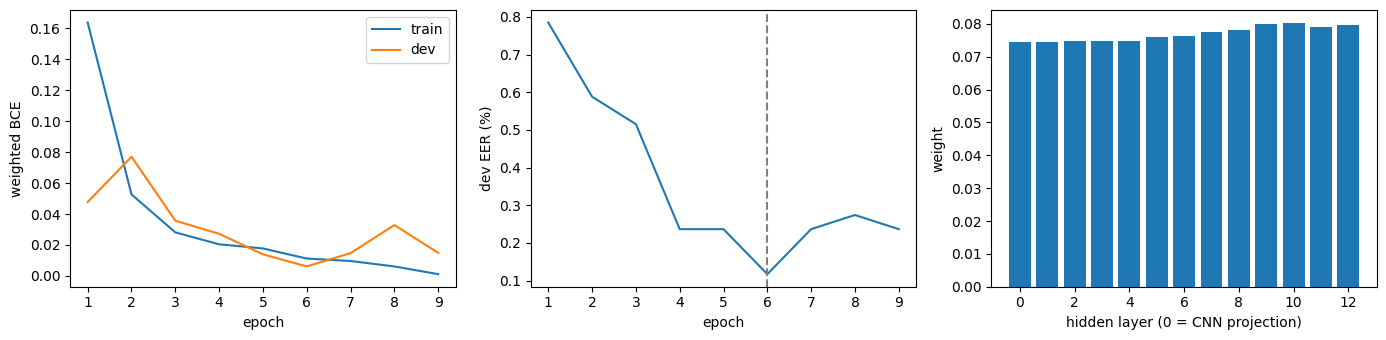

,epoch,train_loss,dev_loss,dev_eer,lr_encoder,seconds
0,1,0.16366,0.04776,0.00785,0.00001,940.89666
1,2,0.05266,0.07701,0.00588,0.00001,932.75701
2,3,0.02815,0.03571,0.00515,0.00001,930.55695
3,4,0.02044,0.02720,0.00237,0.00001,927.41074
4,5,0.01777,0.01395,0.00237,0.00001,923.68575
5,6,0.01123,0.00616,0.00117,0.00000,922.32647
6,7,0.00966,0.01471,0.00237,0.00000,923.06329
7,8,0.00613,0.03287,0.00274,0.00000,921.33706
8,9,0.00116,0.01490,0.00237,0.00000,920.53168


In [7]:
hist = pd.DataFrame(history)
best = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
layer_w = torch.softmax(best["model_state_dict"]["layer_logits"].float().cpu(), dim=0).numpy()
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].plot(hist["epoch"], hist["train_loss"], label="train")
ax[0].plot(hist["epoch"], hist["dev_loss"], label="dev")
ax[0].set_xlabel("epoch")
ax[0].set_ylabel("weighted BCE")
ax[0].legend()
ax[1].plot(hist["epoch"], hist["dev_eer"] * 100)
ax[1].axvline(best_epoch, color="grey", linestyle="--")
ax[1].set_xlabel("epoch")
ax[1].set_ylabel("dev EER (%)")
ax[2].bar(range(len(layer_w)), layer_w)
ax[2].set_xlabel("hidden layer (0 = CNN projection)")
ax[2].set_ylabel("weight")
plt.tight_layout()
plt.show()
hist.round(5)

## Final checkpoint

The best weights are reloaded and dev is re-scored; the result must reproduce the EER recorded during training, and agree with an independent EER implementation. The checkpoint then gets the configuration and provenance needed by notebooks 03–04 and the backend.

In [8]:
final = build_model()
final.load_state_dict(best["model_state_dict"])
labels, logits, _ = predict(final, make_loader(dev_df, "dev", train=False))
dev_eer, dev_thr = U.eer(labels, logits)
step = 1.0 / min((labels == 0).sum(), (labels == 1).sum())
if abs(dev_eer - best["dev_eer"]) > step:
    raise AssertionError(f"reloaded dev EER {dev_eer} != recorded {best['dev_eer']}")
if abs(dev_eer - U.eer_independent(labels, logits)) > 1.5 * step:
    raise AssertionError("official and independent EER disagree")

rates = U.rates_at_threshold(labels, logits, dev_thr)
checkpoint = {
    "model_state_dict": best["model_state_dict"],
    "model": "wav2vec2",
    "pretrained": W2V_NAME,
    "encoder_config": final.encoder.config.to_dict(),
    "epoch": best["epoch"],
    "seed": SEED,
    "dev_eer": dev_eer,
    "threshold_logit": dev_thr,
    "threshold_prob": float(torch.sigmoid(torch.tensor(dev_thr))),
    "threshold_source": "dev_eer",
    "layer_weights": layer_w.tolist(),
    "config": {"batch_size": BATCH_SIZE, "epochs": EPOCHS, "min_epochs": MIN_EPOCHS, "patience": PATIENCE,
               "lr_encoder": LR_ENCODER, "lr_head": LR_HEAD, "weight_decay": WEIGHT_DECAY,
               "warmup_fraction": WARMUP_FRACTION, "grad_clip": GRAD_CLIP, "class_weight": CLASS_WEIGHT,
               "rawboost": {"algo": 5, **rawboost.LNL, **rawboost.ISD}, "amp": AMP},
    "history": history,
    "utils_sha256": U.utils_sha256(),
    "prep_manifest_sha256": prep["manifest_sha256"],
    "versions": {"torch": torch.__version__, "transformers": transformers.__version__},
}
torch.save(checkpoint, ckpt_path)
print(json.dumps({k: checkpoint[k] for k in ("epoch", "dev_eer", "threshold_logit", "threshold_prob")}, indent=2))
pd.Series(rates).to_frame("dev at dev-EER threshold")

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base
Key                          | Status     |  | 
-----------------------------+------------+--+-
wav2vec2.masked_spec_embed   | UNEXPECTED |  | 
quantizer.codevectors        | UNEXPECTED |  | 
project_hid.bias             | UNEXPECTED |  | 
project_q.weight             | UNEXPECTED |  | 
quantizer.weight_proj.bias   | UNEXPECTED |  | 
project_q.bias               | UNEXPECTED |  | 
quantizer.weight_proj.weight | UNEXPECTED |  | 
project_hid.weight           | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


{
  "epoch": 6,
  "dev_eer": 0.001171761244035579,
  "threshold_logit": 4.28126859664917,
  "threshold_prob": 0.9863634705543518
}


,dev at dev-EER threshold
threshold_logit,4.281269
tp,22270.000000
tn,2545.000000
fp,3.000000
fn,26.000000
spoof_recall,0.998834
spoof_precision,0.999865
bonafide_rejection_rate,0.001177
spoof_miss_rate,0.001166
accuracy,0.998833
